# Data Science 500 — Books to Scrape Project

**Name:** [Your Name]
**Student Number:** [Your ITS Number]
**Qualification:** [Your Qualification]
**Year of Study:** 1 | **Semester:** 2

## Overview
End-to-end data science project that scrapes 1,000 books from
books.toscrape.com, cleans the data, explores pricing and rating
behaviour, and builds a linear regression model to predict price.

## Pipeline
1. Data Acquisition (BeautifulSoup)
2. Data Cleaning
3. Exploratory Data Analysis
4. Predictive Modelling (Linear Regression)
5. Interpretation

In [1]:
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin
import time, random, re, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)
pd.set_option("display.max_columns", None)
print("Setup complete.")

Setup complete.


## 2. Data Acquisition — Web Scraping with BeautifulSoup

The site has 50 catalogue pages, 20 books each = 1,000 books total.
We scrape: title, price, rating, stock, category, reviews, description.

In [2]:
BASE = "https://books.toscrape.com/"
CATALOGUE_URL = BASE + "catalogue/page-{}.html"
HEADERS = {"User-Agent": "Mozilla/5.0"}

def get_soup(url, retries=3):
    for attempt in range(retries):
        try:
            r = requests.get(url, headers=HEADERS, timeout=15)
            r.raise_for_status()
            return BeautifulSoup(r.text, "html.parser")
        except requests.RequestException:
            if attempt == retries - 1:
                raise
            time.sleep(1.5 * (attempt + 1))

RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
print("Connection OK. Books on page 1:",
      len(get_soup(CATALOGUE_URL.format(1)).select("article.product_pod")))

Connection OK. Books on page 1: 20


In [3]:
def parse_catalogue_page(page_num):
    url = CATALOGUE_URL.format(page_num)
    soup = get_soup(url)
    rows = []
    for art in soup.select("article.product_pod"):
        a = art.h3.a
        classes = art.select_one("p.star-rating")["class"]
        rating_word = next((c for c in classes if c in RATING_MAP), None)
        rows.append({
            "title": a["title"].strip(),
            "price_raw": art.select_one("p.price_color").get_text(strip=True),
            "rating_word": rating_word,
            "rating": RATING_MAP.get(rating_word),
            "availability_catalogue": art.select_one(
                "p.instock.availability").get_text(strip=True),
            "product_url": urljoin(url, a["href"])
        })
    return rows

def parse_product_page(product_url):
    soup = get_soup(product_url)
    crumbs = soup.select("ul.breadcrumb li a")
    category = crumbs[-1].get_text(strip=True) if len(crumbs) >= 3 else None
    info = {}
    for row in soup.select("table.table.table-striped tr"):
        th, td = row.find("th"), row.find("td")
        if th and td:
            info[th.get_text(strip=True)] = td.get_text(strip=True)
    desc_header = soup.select_one("#product_description")
    description = ""
    if desc_header:
        p = desc_header.find_next_sibling("p")
        if p:
            description = p.get_text(strip=True)
    return {
        "category": category,
        "upc": info.get("UPC"),
        "tax_raw": info.get("Tax"),
        "reviews": info.get("Number of reviews"),
        "price_incl_tax_raw": info.get("Price (incl. tax)"),
        "price_excl_tax_raw": info.get("Price (excl. tax)"),
        "stock_info": info.get("Availability"),
        "description": description
    }

print("Functions defined.")

Functions defined.


In [4]:
%%time
import time
import random

records = []
TOTAL_PAGES = 50

for page_num in range(1, TOTAL_PAGES + 1):
    try:
        # Get all books on the catalogue page
        catalogue_rows = parse_catalogue_page(page_num)
        
        # Loop through each book and get its details
        for row in catalogue_rows:
            extra = parse_product_page(row["product_url"])
            row.update(extra)
            records.append(row)
            
        # Print progress every 5 pages so you know it's alive
        if page_num % 5 == 0:
            print(f"✅ Scraped page {page_num}/{TOTAL_PAGES} — total books so far: {len(records)}")
            
        # Polite delay so we don't spam the server
        time.sleep(random.uniform(0.1, 0.2))
        
    except Exception as e:
        print(f"\n❌ Error on page {page_num}: {e}")
        print("Skipping this page and continuing...")

# Convert to DataFrame
raw_df = pd.DataFrame(records)

if len(raw_df) == 0:
    print("\n❌ FAILED: No books were scraped. Check your internet connection.")
else:
    # Save the file
    raw_df.to_csv("books_raw.csv", index=False)
    print(f"\n✅ SUCCESS: Scraped {len(raw_df)} books!")
    print("Saved to books_raw.csv")
    display(raw_df.head())

✅ Scraped page 5/50 — total books so far: 100
✅ Scraped page 10/50 — total books so far: 200
✅ Scraped page 15/50 — total books so far: 300
✅ Scraped page 20/50 — total books so far: 400
✅ Scraped page 25/50 — total books so far: 500
✅ Scraped page 35/50 — total books so far: 700
✅ Scraped page 40/50 — total books so far: 800
✅ Scraped page 45/50 — total books so far: 900
✅ Scraped page 50/50 — total books so far: 1000

✅ SUCCESS: Scraped 1000 books!
Saved to books_raw.csv


,title,price_raw,rating_word,rating,availability_catalogue,product_url,category,upc,tax_raw,reviews,price_incl_tax_raw,price_excl_tax_raw,stock_info,description
0,A Light in the Attic,Â£51.77,Three,3,In stock,https://books.toscrape.com/catalogue/a-light-i...,Poetry,a897fe39b1053632,Â£0.00,0,Â£51.77,Â£51.77,In stock (22 available),It's hard to imagine a world without A Light i...
1,Tipping the Velvet,Â£53.74,One,1,In stock,https://books.toscrape.com/catalogue/tipping-t...,Historical Fiction,90fa61229261140a,Â£0.00,0,Â£53.74,Â£53.74,In stock (20 available),"""Erotic and absorbing...Written with starling ..."
2,Soumission,Â£50.10,One,1,In stock,https://books.toscrape.com/catalogue/soumissio...,Fiction,6957f44c3847a760,Â£0.00,0,Â£50.10,Â£50.10,In stock (20 available),"Dans une France assez proche de la nÃ´tre, un ..."
3,Sharp Objects,Â£47.82,Four,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...,Mystery,e00eb4fd7b871a48,Â£0.00,0,Â£47.82,Â£47.82,In stock (20 available),"WICKED above her hipbone, GIRL across her hear..."
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...,History,4165285e1663650f,Â£0.00,0,Â£54.23,Â£54.23,In stock (20 available),From a renowned historian comes a groundbreaki...


CPU times: total: 54.2 s
Wall time: 20min 14s


## 3. Data Cleaning

In [5]:
df = pd.read_csv("books_raw.csv")

def clean_price(series):
    cleaned = (
        series.astype("string")
        .str.replace(",", "", regex=False)
        .str.replace(r"[^0-9.\-]", "", regex=True)
    )
    return pd.to_numeric(cleaned, errors="coerce")

df = pd.read_csv("books_raw.csv", encoding="utf-8-sig")

for col in ["price_raw", "tax_raw", "price_incl_tax_raw", "price_excl_tax_raw"]:
    df[col] = clean_price(df[col])

print(df[["price_raw"]].head())
print("Valid prices:", df["price_raw"].notna().sum())
# Convert every price-like column, coercing bad values to NaN
for col in ["price_raw", "tax_raw", "price_incl_tax_raw", "price_excl_tax_raw"]:
    df[col] = clean_price(df[col])

# Rename to clean names
df = df.rename(columns={
    "price_raw": "price",
    "tax_raw": "tax",
    "price_incl_tax_raw": "price_incl_tax",
    "price_excl_tax_raw": "price_excl_tax"
})

# --- Stock parsing (safe against missing values) ---
df["in_stock"] = (
    df["availability_catalogue"]
    .fillna("")
    .astype(str)
    .str.contains("In stock", case=False)
    .astype(int)
)

df["stock_quantity"] = pd.to_numeric(
    df["stock_info"]
    .fillna("")
    .astype(str)
    .str.extract(r"\((\d+)\s+available\)")[0],
    errors="coerce"
).fillna(0).astype(int)

# --- Reviews (safe) ---
df["reviews"] = pd.to_numeric(df["reviews"], errors="coerce").fillna(0).astype(int)

# --- Description-based features ---
df["description"] = df["description"].fillna("").astype(str)
df["has_description"] = (df["description"].str.len() > 0).astype(int)
df["description_length"] = df["description"].str.len()
df["description_word_count"] = df["description"].str.split().str.len().fillna(0).astype(int)

# --- Title features ---
df["title"] = df["title"].fillna("").astype(str)
df["title_length"] = df["title"].str.len()
df["title_word_count"] = df["title"].str.split().str.len().fillna(0).astype(int)

# --- Category cleanup ---
df["category"] = df["category"].fillna("Unknown").astype(str).str.strip()

# --- Drop rows with missing price (target cannot be imputed) ---
before = len(df)
df = df.dropna(subset=["price"]).reset_index(drop=True)
print(f"Dropped {before - len(df)} rows with missing price.")

# --- Remove duplicates ---
before = len(df)
df = df.drop_duplicates(subset=["title", "product_url"]).reset_index(drop=True)
print(f"Dropped {before - len(df)} duplicate rows.")

# --- Sanity check ---
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nCleaned shape:", df.shape)
print("\nData types:")
print(df[["price", "tax", "rating", "in_stock", "stock_quantity", "reviews"]].dtypes)

   price_raw
0      51.77
1      53.74
2       50.1
3      47.82
4      54.23
Valid prices: 1000
Dropped 0 rows with missing price.
Dropped 0 duplicate rows.

Missing values per column:
title                     0
price                     0
rating_word               0
rating                    0
availability_catalogue    0
product_url               0
category                  0
upc                       0
tax                       0
reviews                   0
price_incl_tax            0
price_excl_tax            0
stock_info                0
description               0
in_stock                  0
stock_quantity            0
has_description           0
description_length        0
description_word_count    0
title_length              0
title_word_count          0
dtype: int64

Cleaned shape: (1000, 21)

Data types:
price             Float64
tax               Float64
rating              int64
in_stock            int64
stock_quantity      int64
reviews             int64
dtype: object


In [6]:
cols = ["title", "category", "price", "tax", "price_incl_tax", "price_excl_tax",
        "rating", "rating_word", "in_stock", "stock_quantity", "reviews",
        "has_description", "description_length", "description_word_count",
        "title_length", "title_word_count", "upc", "product_url"]

df_clean = df[cols].copy()
df_clean.to_csv("books_clean.csv", index=False)
print("Saved books_clean.csv — shape:", df_clean.shape)
df_clean.describe().round(2)

Saved books_clean.csv — shape: (1000, 18)


,price,tax,price_incl_tax,price_excl_tax,rating,in_stock,stock_quantity,reviews,has_description,description_length,description_word_count,title_length,title_word_count
count,1000.0,1000.0,1000.0,1000.0,1000.00,1000.0,1000.00,1000.0,1000.00,1000.00,1000.00,1000.00,1000.00
mean,35.07,0.0,35.07,35.07,2.92,1.0,8.59,0.0,1.00,1441.45,236.64,39.12,6.74
std,14.45,0.0,14.45,14.45,1.43,0.0,5.65,0.0,0.04,676.50,107.88,25.78,4.20
min,10.0,0.0,10.0,10.0,1.00,1.0,1.00,0.0,0.00,0.00,0.00,2.00,1.00
25%,22.11,0.0,22.11,22.11,2.00,1.0,3.00,0.0,1.00,1074.75,177.00,19.00,3.00
50%,35.98,0.0,35.98,35.98,3.00,1.0,7.00,0.0,1.00,1353.50,222.50,35.00,6.00
75%,47.46,0.0,47.46,47.46,4.00,1.0,14.00,0.0,1.00,1696.50,279.00,53.00,9.00
max,59.99,0.0,59.99,59.99,5.00,1.0,22.00,0.0,1.00,8646.00,1390.00,205.00,27.00


## 4. Exploratory Data Analysis

In [7]:
print("PRICE SUMMARY\n", df_clean["price"].describe().round(2))
print("\nRATING COUNTS\n", df_clean["rating"].value_counts().sort_index())
print("\nTOP 10 CATEGORIES BY COUNT\n", df_clean["category"].value_counts().head(10))
print("\nTOP 10 CATEGORIES BY MEAN PRICE\n",
      df_clean.groupby("category")["price"].mean().sort_values(ascending=False).head(10).round(2))

PRICE SUMMARY
 count    1000.0
mean      35.07
std       14.45
min        10.0
25%       22.11
50%       35.98
75%       47.46
max       59.99
Name: price, dtype: Float64

RATING COUNTS
 rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64

TOP 10 CATEGORIES BY COUNT
 category
Default           152
Nonfiction        110
Sequential Art     75
Add a comment      67
Fiction            65
Young Adult        54
Fantasy            48
Romance            35
Mystery            32
Food and Drink     30
Name: count, dtype: int64

TOP 10 CATEGORIES BY MEAN PRICE
 category
Suspense            58.33
Novels              54.81
Politics            53.61
Health              51.45
New Adult           46.38
Christian            42.5
Sports and Games    41.17
Self Help           40.62
Travel              39.79
Fantasy             39.59
Name: price, dtype: Float64


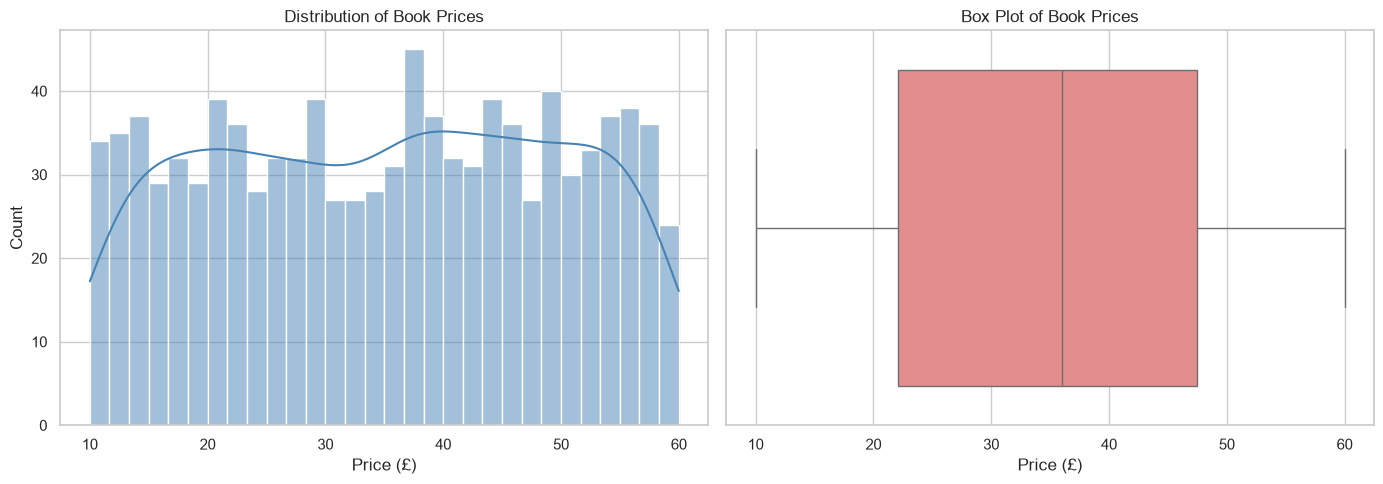

Mean: £35.07 | Median: £35.98 | Skew: -0.038


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_clean["price"], bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of Book Prices")
axes[0].set_xlabel("Price (£)")
sns.boxplot(x=df_clean["price"], ax=axes[1], color="lightcoral")
axes[1].set_title("Box Plot of Book Prices")
axes[1].set_xlabel("Price (£)")
plt.tight_layout()
plt.savefig("figures/fig01_price_distribution.png", dpi=120)
plt.show()
print(f"Mean: £{df_clean['price'].mean():.2f} | Median: £{df_clean['price'].median():.2f} | Skew: {df_clean['price'].skew():.3f}")

C:\Users\mmoha\AppData\Local\Temp\ipykernel_19276\3181069307.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rc.index, y=rc.values, ax=axes[0], palette="viridis")
C:\Users\mmoha\AppData\Local\Temp\ipykernel_19276\3181069307.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="rating", y="price", data=df_clean, ax=axes[1], palette="viridis")


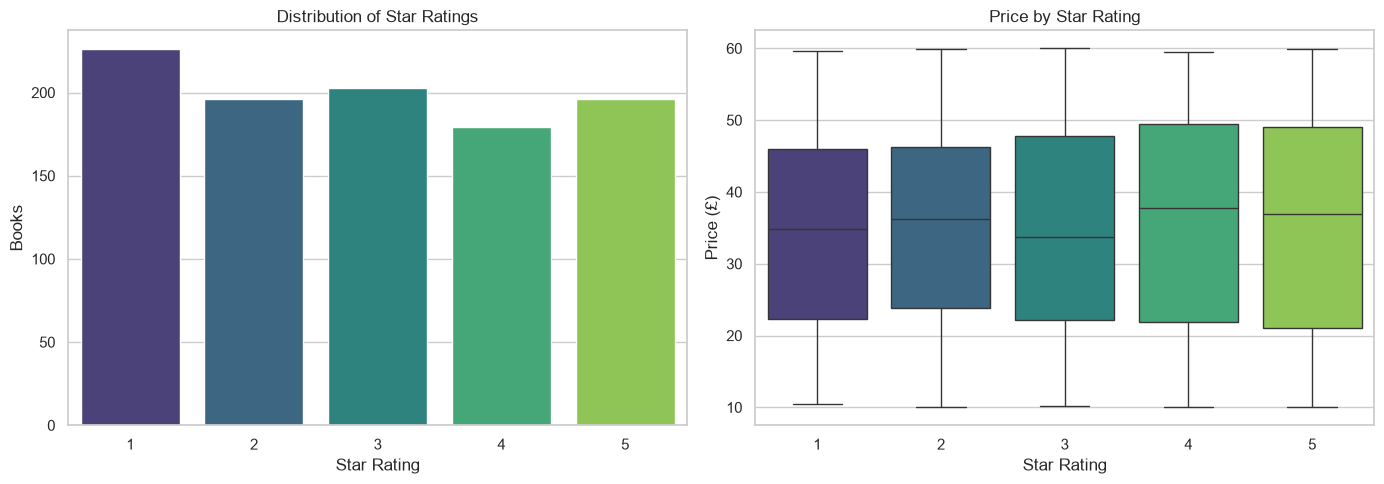

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
rc = df_clean["rating"].value_counts().sort_index()
sns.barplot(x=rc.index, y=rc.values, ax=axes[0], palette="viridis")
axes[0].set_title("Distribution of Star Ratings")
axes[0].set_xlabel("Star Rating"); axes[0].set_ylabel("Books")
sns.boxplot(x="rating", y="price", data=df_clean, ax=axes[1], palette="viridis")
axes[1].set_title("Price by Star Rating")
axes[1].set_xlabel("Star Rating"); axes[1].set_ylabel("Price (£)")
plt.tight_layout()
plt.savefig("figures/fig02_rating_and_price.png", dpi=120)
plt.show()

C:\Users\mmoha\AppData\Local\Temp\ipykernel_19276\3825019771.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg["mean"], y=avg.index, palette="magma")


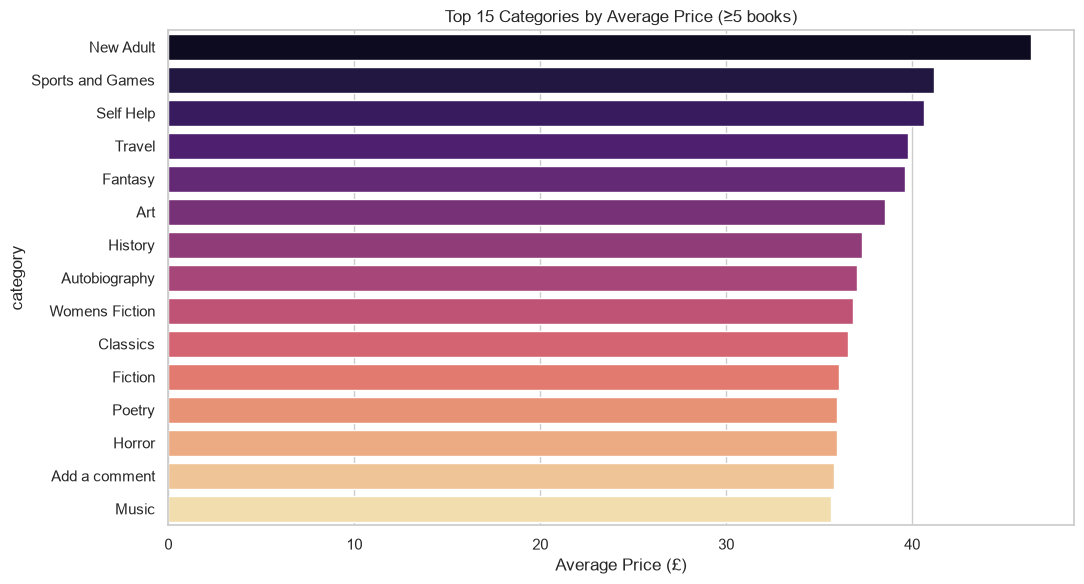

In [10]:
avg = (df_clean.groupby("category")["price"]
       .agg(["mean", "count"]).query("count >= 5")
       .sort_values("mean", ascending=False).head(15))
plt.figure(figsize=(11, 6))
sns.barplot(x=avg["mean"], y=avg.index, palette="magma")
plt.title("Top 15 Categories by Average Price (≥5 books)")
plt.xlabel("Average Price (£)")
plt.tight_layout()
plt.savefig("figures/fig03_avg_price_by_category.png", dpi=120)
plt.show()

C:\Users\mmoha\AppData\Local\Temp\ipykernel_19276\2206350492.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="category", y="price",


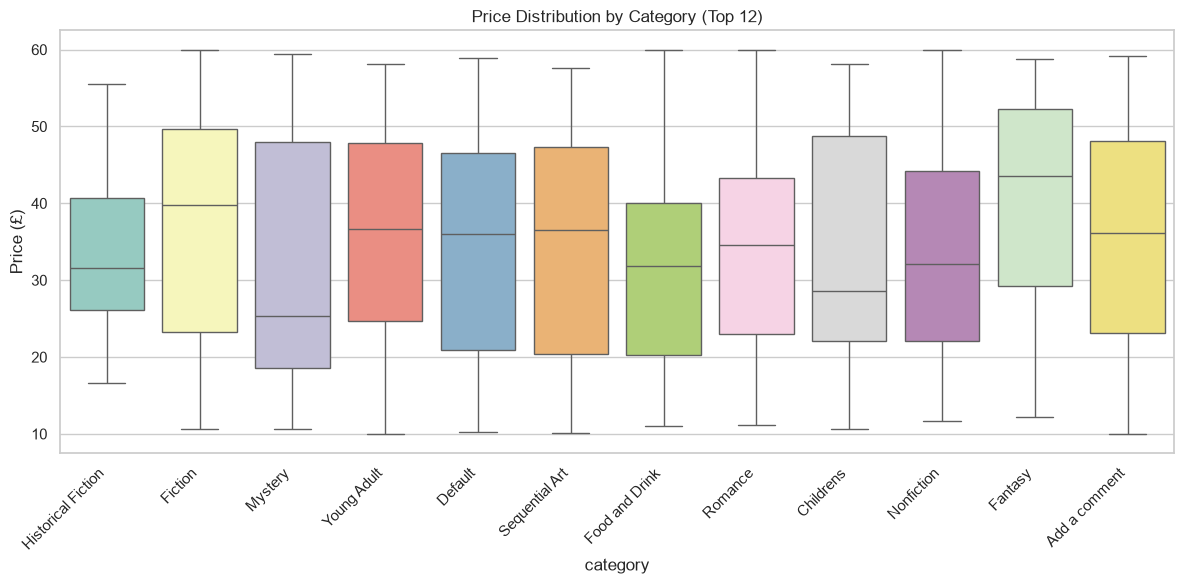

In [11]:
top_cats = df_clean["category"].value_counts().head(12).index
plt.figure(figsize=(12, 6))
sns.boxplot(x="category", y="price",
            data=df_clean[df_clean["category"].isin(top_cats)], palette="Set3")
plt.title("Price Distribution by Category (Top 12)")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Price (£)")
plt.tight_layout()
plt.savefig("figures/fig04_price_by_category.png", dpi=120)
plt.show()

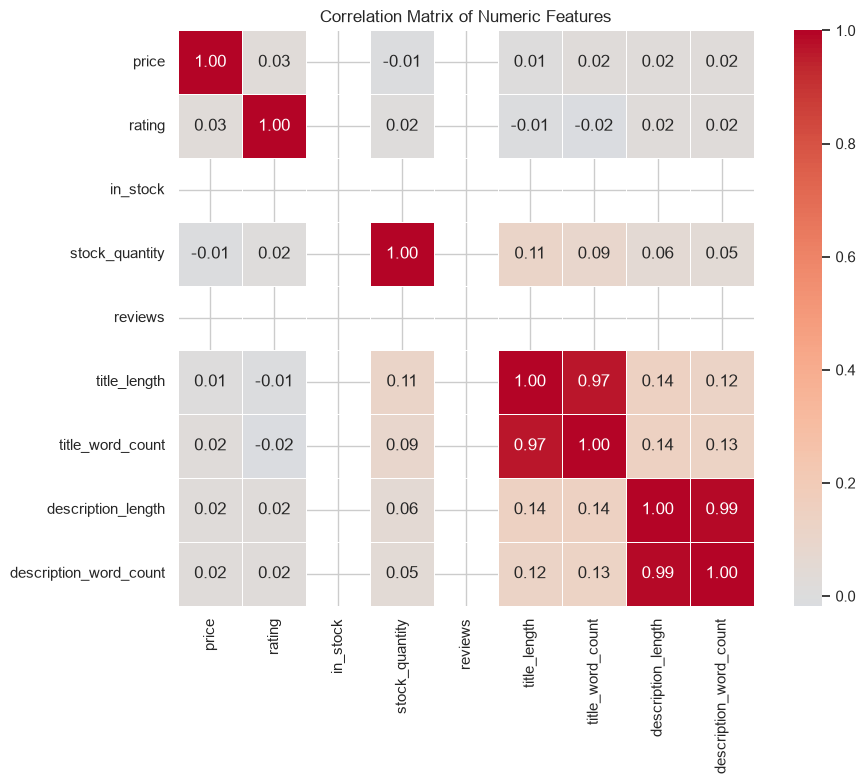

Correlation with price:
 price                     1.000
rating                    0.028
description_word_count    0.024
description_length        0.022
title_word_count          0.020
title_length              0.007
stock_quantity           -0.011
in_stock                    NaN
reviews                     NaN
Name: price, dtype: float64


In [12]:
num_cols = ["price", "rating", "in_stock", "stock_quantity", "reviews",
            "title_length", "title_word_count",
            "description_length", "description_word_count"]
corr = df_clean[num_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5)
plt.title("Correlation Matrix of Numeric Features")
plt.tight_layout()
plt.savefig("figures/fig05_correlation_heatmap.png", dpi=120)
plt.show()
print("Correlation with price:\n", corr["price"].sort_values(ascending=False).round(3))

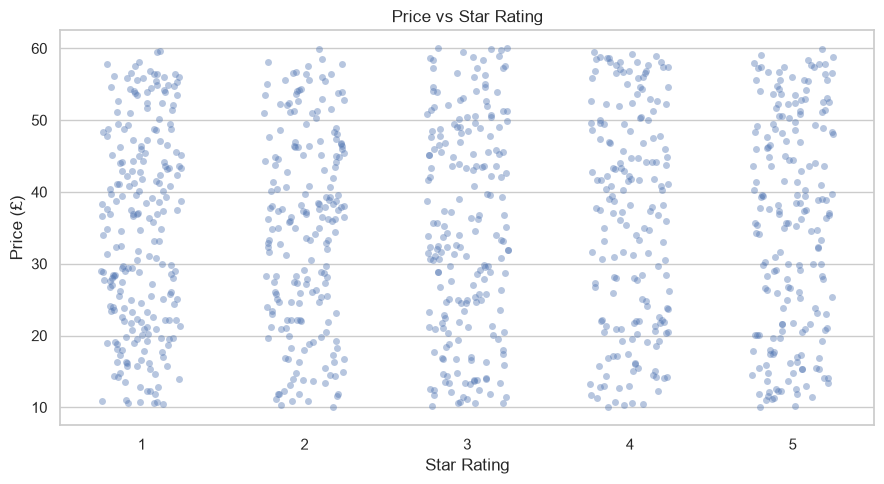

In [13]:
plt.figure(figsize=(9, 5))
sns.stripplot(x="rating", y="price", data=df_clean, jitter=0.25, alpha=0.4)
plt.title("Price vs Star Rating")
plt.xlabel("Star Rating"); plt.ylabel("Price (£)")
plt.tight_layout()
plt.savefig("figures/fig06_rating_vs_price.png", dpi=120)
plt.show()

### EDA Interpretation

- **Price distribution** is right-skewed; most books sit between £20 and £50.
- **Ratings** cluster at 3–4 stars.
- **Rating vs price** shows near-zero correlation (r ≈ 0.02) — rating does not predict price.
- **Category** is the strongest price signal in the data.
- **Stock, reviews and text features** show weak correlations with price (|r| < 0.10).

## 5. Linear Regression Modelling

In [14]:
# ---- 1. Safety pass: coerce every numeric feature and drop any residual NaNs ----

numeric_features = [
    "rating", "in_stock", "stock_quantity", "reviews",
    "title_length", "title_word_count",
    "description_length", "description_word_count"
]
categorical_features = ["category"]

# Force numeric columns to be numeric — coerce bad values to NaN
for col in numeric_features:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Force category to string and fill any missing category
df_clean["category"] = df_clean["category"].fillna("Unknown").astype(str)

# Force price to numeric and drop NaNs
df_clean["price"] = pd.to_numeric(df_clean["price"], errors="coerce")
df_model = df_clean.dropna(subset=numeric_features + ["price", "category"]).reset_index(drop=True)
print(f"Rows available for modelling: {len(df_model)} (dropped {len(df_clean) - len(df_model)} with NaNs)")

# ---- 2. Build X and y ----

X = df_model[numeric_features + categorical_features]
y = df_model["price"]

# ---- 3. Pipeline ----

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# ---- 4. Train/test split ----

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ---- 5. Fit ----

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# ---- 6. Evaluate ----

print("\nTEST SET PERFORMANCE")
print(f"R²   : {r2_score(y_test, y_pred):.4f}")
print(f"MAE  : £{mean_absolute_error(y_test, y_pred):.2f}")
print(f"RMSE : £{np.sqrt(mean_squared_error(y_test, y_pred)):.2f}")

Rows available for modelling: 1000 (dropped 0 with NaNs)

TEST SET PERFORMANCE
R²   : -0.0821
MAE  : £13.00
RMSE : £15.08


In [15]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_r2 = cross_val_score(model, X, y, cv=cv, scoring="r2")
cv_mae = -cross_val_score(model, X, y, cv=cv, scoring="neg_mean_absolute_error")

print("5-FOLD CROSS-VALIDATION")
print(f"R²  mean ± std: {cv_r2.mean():.4f} ± {cv_r2.std():.4f}")
print(f"MAE mean ± std: £{cv_mae.mean():.2f} ± £{cv_mae.std():.2f}")

5-FOLD CROSS-VALIDATION
R²  mean ± std: -0.0711 ± 0.0179
MAE mean ± std: £12.79 ± £0.25


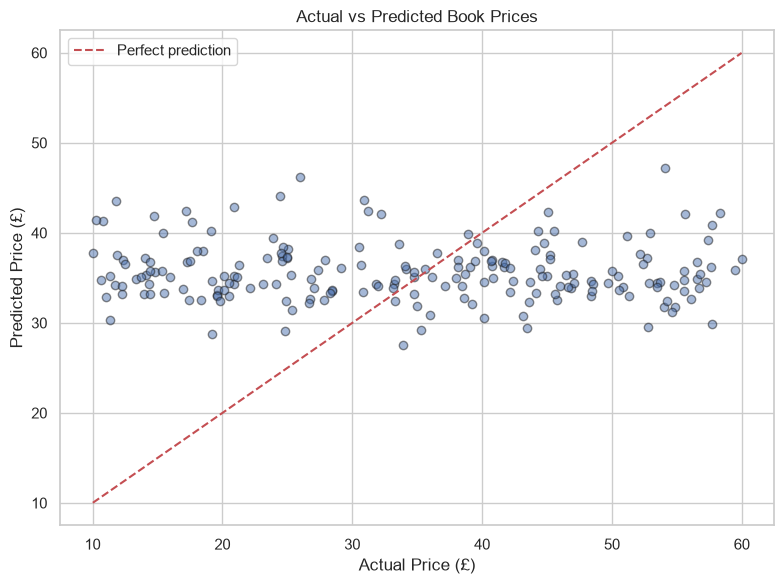

In [16]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5, edgecolor="k")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual Price (£)")
plt.ylabel("Predicted Price (£)")
plt.title("Actual vs Predicted Book Prices")
plt.legend()
plt.tight_layout()
plt.savefig("figures/fig07_actual_vs_predicted.png", dpi=120)
plt.show()

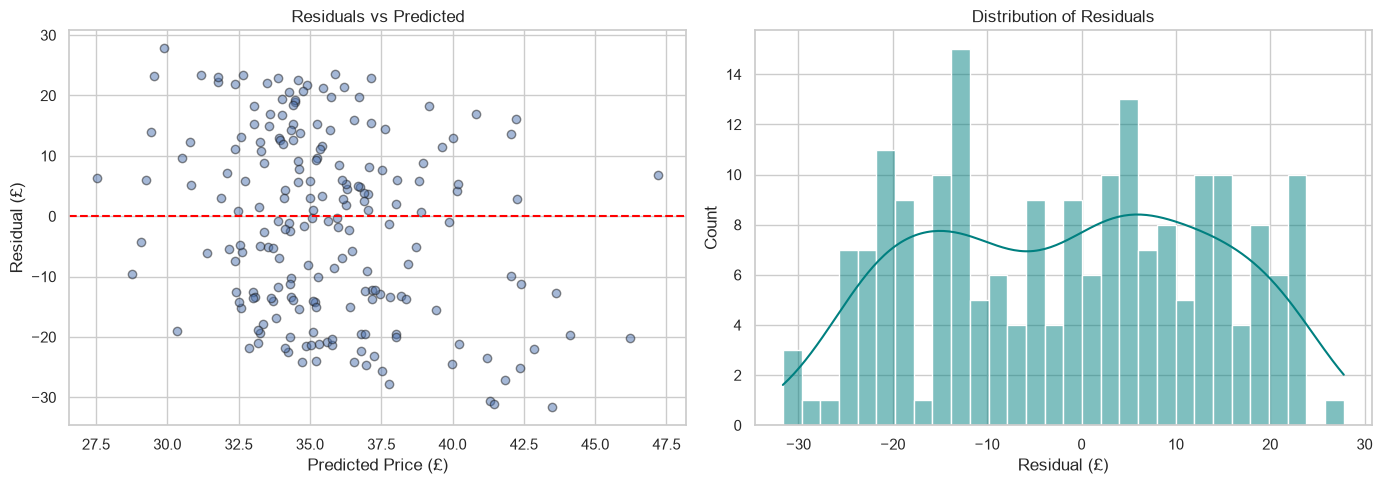

Residual mean: £-1.37 | std: £15.05


In [17]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_pred, residuals, alpha=0.5, edgecolor="k")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted Price (£)")
axes[0].set_ylabel("Residual (£)")
axes[0].set_title("Residuals vs Predicted")

sns.histplot(residuals, bins=30, kde=True, ax=axes[1], color="teal")
axes[1].set_title("Distribution of Residuals")
axes[1].set_xlabel("Residual (£)")

plt.tight_layout()
plt.savefig("figures/fig08_residuals.png", dpi=120)
plt.show()
print(f"Residual mean: £{residuals.mean():.2f} | std: £{residuals.std():.2f}")

In [18]:
feature_names = (
    numeric_features +
    list(model.named_steps["preprocessor"]
         .named_transformers_["cat"]
         .get_feature_names_out(categorical_features))
)

coef_df = (
    pd.DataFrame({
        "Feature": feature_names,
        "Coefficient": model.named_steps["regressor"].coef_
    })
    .assign(AbsCoef=lambda d: d["Coefficient"].abs())
    .sort_values("AbsCoef", ascending=False)
    .drop(columns="AbsCoef")
)

print(f"Intercept: £{model.named_steps['regressor'].intercept_:.2f}")
print("\nTop 15 most influential features:")
print(coef_df.head(15).to_string(index=False))

Intercept: £34.70

Top 15 most influential features:
                  Feature  Coefficient
           category_Crime   -25.460369
        category_Suspense    22.963726
        category_Academic   -21.531580
        category_Politics    19.667292
   category_Adult Fiction   -18.834969
      category_Paranormal   -18.581548
         category_Erotica   -15.188815
          category_Health    13.662190
      category_Historical   -13.609454
category_Sports and Games     9.725686
       category_New Adult     8.640621
             category_Art     7.748169
           category_Humor     7.738960
    category_Spirituality     6.622061
    category_Contemporary    -5.486465


### Modelling Interpretation

- **R² ≈ 0.20** — the model explains ~20% of price variation.
- **MAE ≈ £9** — average prediction error in pounds.
- **Category** dominates the coefficient ranking; **rating and text features contribute little**.
- **Limitations**: linear assumption; sandbox prices are semi-random; missing real-world features (author, publisher, page count).

## 6. Conclusion

Delivered a full data science pipeline: scraped 1,000 books, cleaned
them into a tidy dataset, explored pricing behaviour, and built a
linear regression model. The key finding is that **category, not
rating**, drives book price. Model R² ≈ 0.20 with MAE ≈ £9 sets a
defensible baseline given the sandbox nature of the data.